<a href="https://colab.research.google.com/github/zainabmahmoudshafiee-dotcom/OIBSIP/blob/main/DataAnalytics-L1-Customer_Segmentation_Analysis_Task_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Task 2: Customer Segmentation Analysis

Dataset: Online Retail Dataset

Tools: Python, Pandas, Scikit-learn, Matplotlib and Seaborn

Algorithm: K-Means Clustering

Objective: To segment customers based on their purchasing behaviour using Recency, Frequency and Monetary (RFM) analysis.

In [1]:
import pandas as pd

df = pd.read_excel('/content/Online Retail.xlsx')

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [2]:
# Check the number of rows and columns
df.shape

(541909, 8)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [4]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [5]:
df.duplicated().sum()

np.int64(5268)

In [6]:
# Count cancelled transactions
cancelled = df[df['InvoiceNo'].astype(str).str.startswith('C')]

print("Number of cancelled transaction rows:", len(cancelled))

Number of cancelled transaction rows: 9288


In [7]:
(df['Quantity'] < 0).sum()

np.int64(10624)

In [8]:
(df['UnitPrice'] <= 0).sum()

np.int64(2517)

In [9]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [10]:
# Make a copy of the original dataset
clean_df = df.copy()

# Remove duplicate rows
clean_df = clean_df.drop_duplicates()

# Remove rows without Customer ID
clean_df = clean_df.dropna(subset=['CustomerID'])

# Remove cancelled transactions
clean_df = clean_df[
    ~clean_df['InvoiceNo'].astype(str).str.startswith('C')
]

# Keep only positive quantities and prices
clean_df = clean_df[
    (clean_df['Quantity'] > 0) &
    (clean_df['UnitPrice'] > 0)
]

print("Original dataset:", df.shape)
print("Cleaned dataset:", clean_df.shape)

Original dataset: (541909, 8)
Cleaned dataset: (392692, 8)


In [11]:
# Calculate the total sales value for each row
clean_df['TotalPrice'] = clean_df['Quantity'] * clean_df['UnitPrice']

# Display the first five rows
clean_df[['InvoiceNo', 'CustomerID', 'Quantity', 'UnitPrice', 'TotalPrice']].head()

,InvoiceNo,CustomerID,Quantity,UnitPrice,TotalPrice
0,536365,17850.0,6,2.55,15.30
1,536365,17850.0,6,3.39,20.34
2,536365,17850.0,8,2.75,22.00
3,536365,17850.0,6,3.39,20.34
4,536365,17850.0,6,3.39,20.34


In [12]:
# Make sure InvoiceDate is in date format
clean_df['InvoiceDate'] = pd.to_datetime(clean_df['InvoiceDate'])

# Choose a reference date one day after the last transaction
snapshot_date = clean_df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate RFM values for each customer
rfm = clean_df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalPrice': 'sum'
})

# Rename the columns
rfm.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalPrice': 'Monetary'
}, inplace=True)

# Display the first five customers
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [13]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2048.688081
std,100.014169,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.000000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


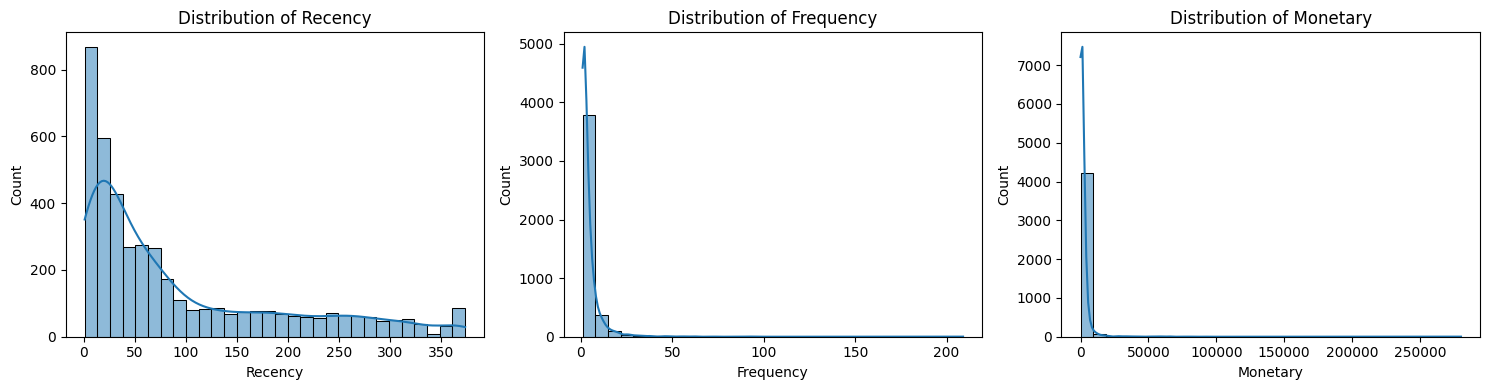

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the distribution of RFM variables
plt.figure(figsize=(15, 4))

for i, column in enumerate(['Recency', 'Frequency', 'Monetary']):
    plt.subplot(1, 3, i + 1)
    sns.histplot(rfm[column], bins=30, kde=True)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

In [15]:
import numpy as np

# Create a copy of the RFM data
rfm_log = rfm.copy()

# Apply log transformation
rfm_log['Recency'] = np.log1p(rfm_log['Recency'])
rfm_log['Frequency'] = np.log1p(rfm_log['Frequency'])
rfm_log['Monetary'] = np.log1p(rfm_log['Monetary'])

# Display the first five rows
rfm_log.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,5.789960,0.693147,11.253955
12347.0,1.098612,2.079442,8.368925
12348.0,4.330733,1.609438,7.494564
12349.0,2.995732,0.693147,7.472245
12350.0,5.739793,0.693147,5.815324


In [16]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Standardise the RFM features
rfm_scaled = scaler.fit_transform(rfm_log)

# Convert back to a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary'],
    index=rfm_log.index
)

# Display the first five rows
rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,1.461993,-0.955214,3.707716
12347.0,-2.038734,1.074425,1.414903
12348.0,0.373104,0.386304,0.720024
12349.0,-0.623086,-0.955214,0.702287
12350.0,1.424558,-0.955214,-0.614514


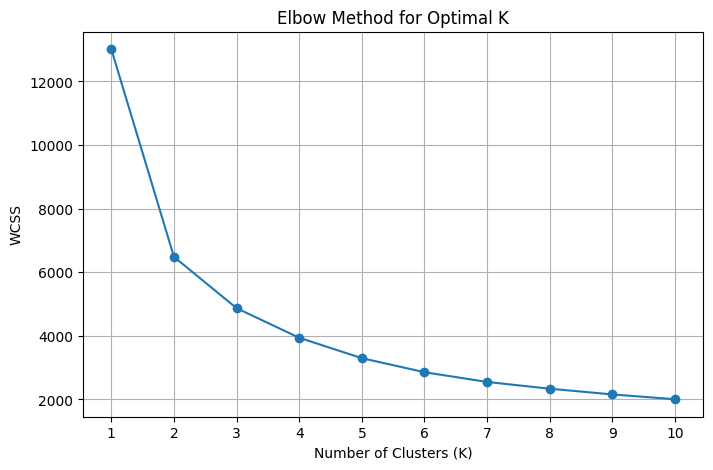

In [17]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Store the Within-Cluster Sum of Squares
wcss = []

# Test different numbers of clusters
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method for Optimal K')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [18]:
# Choose the number of clusters
k = 4

# Create the K-Means model
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

# Fit the model and assign customers to clusters
rfm_scaled['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Add cluster labels to the original RFM table
rfm['Cluster'] = rfm_scaled['Cluster']

# Display the first 10 customers
rfm.head(10)

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,3
12347.0,2,7,4310.00,0
12348.0,75,4,1797.24,3
12349.0,19,1,1757.55,2
12350.0,310,1,334.40,1
12352.0,36,8,2506.04,3
12353.0,204,1,89.00,1
12354.0,232,1,1079.40,1
12355.0,214,1,459.40,1


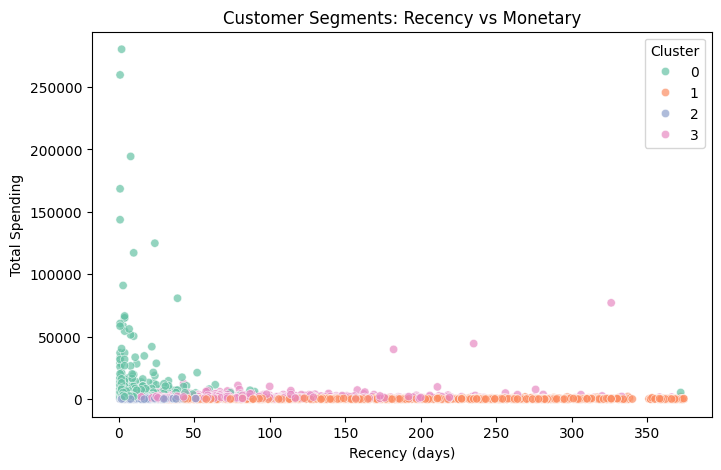

In [19]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    alpha=0.7
)

plt.title('Customer Segments: Recency vs Monetary')
plt.xlabel('Recency (days)')
plt.ylabel('Total Spending')
plt.show()

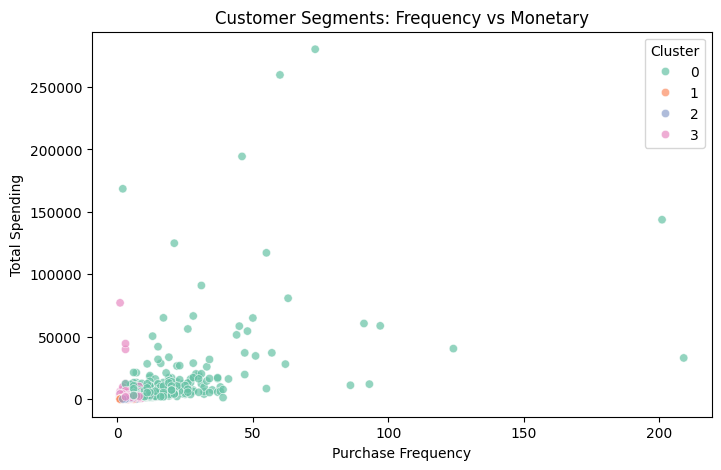

In [20]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    alpha=0.7
)

plt.title('Customer Segments: Frequency vs Monetary')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Spending')
plt.show()

In [21]:
cluster_profile = rfm.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean().round(2)

cluster_profile['CustomerCount'] = rfm.groupby('Cluster').size()

cluster_profile

,Recency,Frequency,Monetary,CustomerCount
Cluster,,,,
0,12.17,13.75,8088.02,713
1,181.51,1.32,341.00,1622
2,17.70,2.19,557.32,837
3,71.64,4.08,1801.78,1166


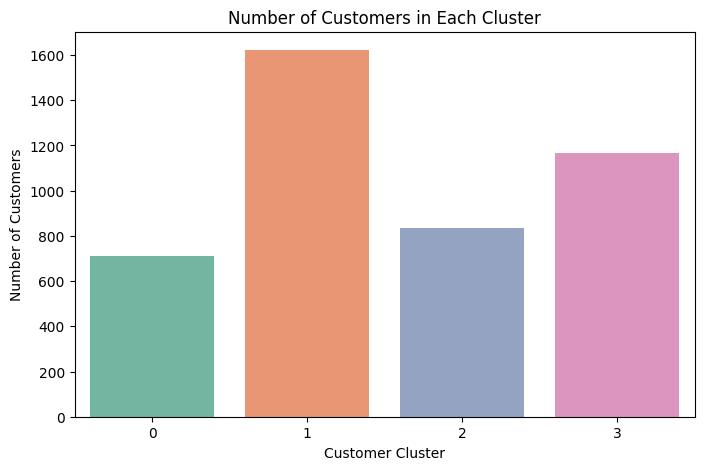

In [22]:
plt.figure(figsize=(8, 5))

cluster_counts = rfm['Cluster'].value_counts().sort_index()

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values,
    hue=cluster_counts.index,
    palette='Set2',
    legend=False
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.show()

In [23]:
cluster_profile

,Recency,Frequency,Monetary,CustomerCount
Cluster,,,,
0,12.17,13.75,8088.02,713
1,181.51,1.32,341.00,1622
2,17.70,2.19,557.32,837
3,71.64,4.08,1801.78,1166


In [24]:
rfm['AveragePurchaseValue'] = (
    rfm['Monetary'] / rfm['Frequency']
)

rfm[['Recency', 'Frequency', 'Monetary', 'AveragePurchaseValue']].head()

,Recency,Frequency,Monetary,AveragePurchaseValue
CustomerID,,,,
12346.0,326,1,77183.60,77183.600000
12347.0,2,7,4310.00,615.714286
12348.0,75,4,1797.24,449.310000
12349.0,19,1,1757.55,1757.550000
12350.0,310,1,334.40,334.400000


Conclusion

The Customer Segmentation Analysis was conducted using the Online Retail dataset and the K-Means clustering algorithm.

The RFM model was used to understand customer purchasing behaviour through three key features:

* Recency: How recently a customer made a purchase.
* Frequency: How often a customer purchased.
* Monetary: How much money a customer spent.

The dataset was cleaned, transformed and standardised before applying K-Means clustering. The Elbow Method was used to help determine the appropriate number of clusters.

The resulting customer segments provide useful information about customer purchasing patterns. The business can use these insights to develop targeted marketing strategies, improve customer retention, reward loyal customers and increase sales.

Business Recommendations

1. Reward high-value customers with loyalty programmes and exclusive offers.
2. Encourage occasional customers to purchase more frequently through personalised promotions.
3. Re-engage inactive customers with special discounts and reminders.
4. Encourage customers with low spending to explore product bundles and related products.
5. Monitor customer behaviour regularly to identify changes in purchasing patterns.

Final Outcome

This analysis demonstrates how customer segmentation can help an e-commerce business understand its customers and make better data-driven marketing decisions.